# Notebook 16: Matter-Wave Gratings, or a Step That Does Nothing

**Goal:** Atoms crossing a standing wave of light diffract into discrete momenta, and two such gratings separated by a free flight form an interferometer. Treat the momentum of the atom
as its configuration, compute Γ for each stage, and find out when the stages compose like a Markov chain.

By the end of this notebook you will be able to:
- Write Γ for one thin grating as a Bessel kernel, $\Gamma_{pq} = J^2_{p-q}(\kappa)$
- Show that gratings compose exactly for amplitudes and not for probabilities, and why (two Bessel addition theorems)
- Test exactly whether the family of gratings is divisible: a hard wall at $\kappa = 1.2024$, and below it a region that is divisible to machine precision but never exactly
- Show a free flight whose Γ is the identity changing the chance of returning to rest from 0.07 to 1 (the Talbot effect)
- See which records turn the interferometer into a Markov chain, and which do something else

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Study copy of `16_matter_wave_gratings.ipynb`. Same code and outputs, plus sections marked
> **📖 In depth**, **🔍 Reading the code** and **🔭 Looking ahead**.
>
> Written 2026-10-25 from the matter-wave gratings spike (`notes/matter-wave-gratings-spike-2026-10-25.md`), a runner-up in the textbook backlog
> (`notes/textbook-concepts-backlog-2026-10-24.md`), prompted by Schleich ch. 19 on atom diffraction. The question: *two gratings with a flight between them form an interferometer; when do
> the stages compose like a Markov chain?* Short answer: never exactly (sometimes to machine precision), and a flight that moves no probability can decide the outcome.
>
> **Prior work.** The Bessel kernel is the continuous-time quantum walk on the integers (de Falco and Tamascelli, arXiv:0801.4515), and its transform is Graf's addition theorem (DLMF §10.23);
> the Talbot behaviour is the kicked-rotor resonance and antiresonance; the position records are Talbot–Lau decoherence (Hornberger, Sipe and Arndt (2004)). The divisibility test is the
> classical factor criterion for characteristic functions (Lukacs); its application to the grating family was not found in our searches (see the 🔭 cell at the end).
>
> Right after this banner: a summary of what Γ explains here and what it doesn't.
---

### 📖 In depth: what Γ explains about gratings, and what it doesn't

**What Γ explains**
- **The diffraction pattern** of one grating: a Bessel kernel (section 1).
- **Whether stages compose stochastically:** a test you can decide with one Fourier transform, the wall at $\kappa = 1.2024$, and why the family is never exactly divisible below it (section 3).
- **Why the flight matters.** Its Γ is the identity, yet the result depends on it: the clearest case in this lab of a stage whose effect is entirely in the phases Γ discards (section 4).
- **Which records matter.** Full records ($\varepsilon = 1$) in the configuration basis give the Markov composite; records in another basis do something else (section 6).

**What Γ does not explain**
- **The Talbot time.** The refocusing at half the Talbot time comes from the phases $p^2t/2$: it is read off the amplitudes, not off Γ.
- **Which basis is "the" configuration.** Momentum and position give opposite pictures (section 5). ISP takes a configuration basis as given.
- **Thick gratings.** If the atom moves during the pulse (the Bragg regime) the clean Bessel kernel is lost.

**Net.** Γ tells you exactly when the stages could be treated as independent random kicks, and here the answer is never exactly, though in one region the defect is below machine precision.

<!-- expansion:16:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** Notebooks 03 and 05 showed indivisibility with abstract matrices. This one uses a real experiment: atoms diffracted by standing waves of light, the
basis of atom and molecule interferometers. Here indivisibility has an exact test, and the most striking case in this lab: a stage whose Γ is the identity that still decides the outcome.

**Prerequisites.**
- Notebooks 02–03: divisibility, and the linear program that tests it.
- Notebook 05: interference in Γ.
- Notebook 06: division events and weak records.
- Notebook 15: Barandes's Schur–Hadamard gauge (used in section 5).
- A little Fourier analysis: a convolution becomes a product. The 🧮 cells cover the rest.

**How to run it.** From the `notebooks/` folder, *Kernel > Restart & Run All*. The first code cell imports from `isp/gratings.py` and `isp/divisibility.py`, so `isp/` must sit next to
`notebooks/`. Needs numpy, scipy and matplotlib. The divisibility map in section 3 takes a few seconds.

**Search-engineer framing.** A ranking pipeline with a stage that reorders nothing (Γ = I) can still change the final ranking, if the stages pass along more than the ranked list. Whether the
pipeline can be replaced by independent random steps is exactly the divisibility question.


<!-- expansion:16:glossary -->
### 📘 Glossary

- **Standing light wave.** Two counter-propagating laser beams; the light intensity varies as $\cos^2$ along the beam, which acts on atoms as a periodic potential.
- **Grating strength κ.** The phase the light imprints at its peak. Larger κ spreads the atom over more momenta.
- **Raman–Nath (thin-grating) regime.** The atom crosses the light so quickly that it doesn't move sideways while inside; the light only imprints a phase $e^{-i\kappa\cos x}$.
- **Kapitza–Dirac effect.** Diffraction of particles (first electrons, later atoms) by a standing light wave.
- **Momentum in units of 2ħk.** The grating changes the atom's sideways momentum by whole multiples of $2\hbar k$, with $k$ the light's wavenumber: two photon recoils, one photon
  absorbed from one beam and one emitted into the other. (The intensity $\cos^2(kX)$ has period half a wavelength.)
- **Bessel function $J_n$.** The Fourier coefficients of $e^{-i\kappa\cos x}$ are $(-i)^nJ_n(\kappa)$.
- **Convolution kernel.** A transition matrix that depends only on the jump $q - p$, not on where you start.
- **Characteristic function.** The Fourier transform of a probability distribution on jumps; composing independent jumps multiplies characteristic functions.
- **Talbot effect.** A grating's near field repeats itself after the Talbot time (here $4\pi$), and shows shifted copies at fractions of it.
- **Total variation distance.** Half the sum of the absolute differences between two probability distributions; 0 for equal, 1 for disjoint.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv, jn_zeros
from isp.divisibility import _intermediate_lp
from isp.gratings import (grid, grating, flight, gamma, char_fn, divisor_kernel, negative_mass, far_weights,
                          two_gratings, TALBOT, KAPPA_WALL)

### 📖 In depth: the idea in plain words

- **The experiment.** Fire atoms through a standing wave of laser light. The light acts like a diffraction grating: the atoms come out moving at a spread of discrete speeds sideways.
- **As a stochastic process.** Each grating is a table of probabilities: from sideways speed $p$ to speed $q$. That table is Γ.
- **The surprise.** Put a second grating after the first, with some empty space between them. The empty space changes no atom's speed, so a probability-only model says it can't matter. But
  at one special distance the second grating sends every atom back to rest (when both gratings have equal strength), and at another it spreads them even more.
- **Why.** The empty space shifts the phases between the speeds, and the second grating turns those phases into probabilities. A process that can't be broken into independent
  probabilistic steps is what Barandes calls indivisible.
- **Records.** Note down the atom's speed in between and the effect disappears: the stages become independent. Note down its position roughly and little changes; note it down
  sharply and the atom is also kicked.
- **For a search engineer.** Two ranking stages with a "no-op" in between, one that reorders nothing, can still change the final ranking if the stages pass along more than the ranked list. A
  log of only the ranked list at each step can't explain it.

## 1. One Grating
An atom crosses a standing light wave so quickly that it doesn't move while inside (the Raman–Nath regime, Schleich §19.3). The light multiplies its wavefunction by $e^{-i\kappa\cos x}$, where
$\kappa$ is the grating strength. In position this is only a phase; in momentum it spreads the atom over multiples of $2\hbar k_L$, two photon recoils (one photon absorbed from one beam,
one emitted into the other), with $k_L$ the light's wavenumber. The light's intensity goes as $\cos^2(k_L X) = (1 + \cos 2k_L X)/2$, so the grating's period is half a wavelength; $x = 2k_L X$
measures position in units where that period is $2\pi$, and we use $2\hbar k_L$ as the unit of momentum.

The model: one period of the grating sampled at $M$ points, with momenta the integers mod $M$. On that ring Γ is the wrapped kernel $\sum_m J^2_{p-q+mM}(\kappa)$, which equals
$J^2_{p-q}(\kappa)$ up to wrap-around terms negligible for $M=64$. The divisibility analysis in section 3 is for the infinite lattice.

<!-- expansion:16:books-schleich -->
### 📚 From the sources: Schleich on atoms and gratings

- **Schleich**, *Quantum Optics in Phase Space*, §19.3 (printed p. 558): "In the Raman-Nath approximation the atom is allowed only to move over a distance which is much less than a
  wavelength of the light."
- Schleich §19.4.2 (printed p. 563), on the discrete momenta: "This quantization does not arise from the quantization of the radiation field. It emerges from the periodicity of the potential,
  namely the mode function of the electromagnetic field."
- Schleich, problem 9.6 (printed pp. 250–251), on the Talbot effect: "there exists a distance from the grating where the original array of wave packets repeats itself. Moreover, at certain
  fractions of that distance the original array has a smaller period."

Schleich's chapter 19 uses a quantized light field. This notebook uses a classical standing wave, the case where his result reduces to the Bessel functions $J_p(\kappa)$.


κ = 0.5:  max |Γ_p0 − J_p(κ)²| = 4.4e-16   Γ is a convolution (same for every start): True
κ = 1.5:  max |Γ_p0 − J_p(κ)²| = 2.2e-16   Γ is a convolution (same for every start): True
κ = 3.0:  max |Γ_p0 − J_p(κ)²| = 2.6e-16   Γ is a convolution (same for every start): True
in the position basis the grating is a phase, so Γ = I: True


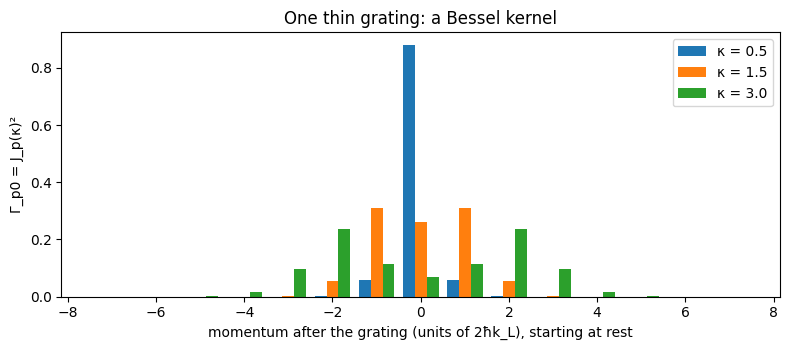

In [2]:
M = 64
x, p, F = grid(M)
for kappa in [0.5, 1.5, 3.0]:
    G = gamma(grating(kappa, M))
    print(f"κ = {kappa}:  max |Γ_p0 − J_p(κ)²| = {np.abs(G[:, 0] - jv(p, kappa) ** 2).max():.1e}   "
          f"Γ is a convolution (same for every start): {np.allclose(G, np.roll(np.roll(G, 5, 0), 5, 1))}")
print(f"in the position basis the grating is a phase, so Γ = I: {np.allclose(gamma(np.diag(np.exp(-1j * 1.5 * np.cos(x)))), np.eye(M))}")

fig, ax = plt.subplots(figsize=(8, 3.6))
n = np.arange(-7, 8)
for i, kappa in enumerate([0.5, 1.5, 3.0]):
    ax.bar(n + (i - 1) * 0.27, jv(n, kappa) ** 2, width=0.27, label=f'κ = {kappa}')
ax.set_xlabel('momentum after the grating (units of 2ħk_L), starting at rest'); ax.set_ylabel('Γ_p0 = J_p(κ)²')
ax.set_title('One thin grating: a Bessel kernel'); ax.legend()
plt.tight_layout(); plt.show()

### 🔍 Reading the code

- **`grid(M)`** gives positions $x_j = 2\pi j/M$, integer momenta in FFT order (0, 1, …, −1) and the unitary discrete Fourier transform `F`.
- **`grating(kappa, M)`** is $F\,\mathrm{diag}(e^{-i\kappa\cos x})\,F^\dagger$: the grating written in the momentum basis.
- **`gamma(U)`** is $|U|^2$ entry by entry.
- **`np.roll(np.roll(G, 5, 0), 5, 1)`** shifts both the start and the end momentum by 5. If Γ is unchanged, it depends only on the difference: a convolution.

<!-- expansion:16:derive-bessel -->
### 🧮 Worked derivation: one grating gives a Bessel kernel

The Jacobi–Anger expansion writes the grating's phase as a sum of momentum kicks:

$$e^{-i\kappa\cos x} = \sum_n (-i)^n J_n(\kappa)\,e^{inx}.$$

The factor $e^{inx}$ adds $n$ units of momentum. So an atom starting at momentum $p$ ends at $p + n$ with amplitude $(-i)^nJ_n(\kappa)$, whatever $p$ is, and

$$\Gamma_{p+n,\,p} = J_n(\kappa)^2 .$$

The probabilities sum to 1 because $\sum_n J_n^2 = 1$. The phases $(-i)^n$ are invisible to one grating's Γ, but they matter when gratings are combined.


<!-- expansion:16:recap-1 -->
### 📝 Recap: section 1

- One thin grating has $\Gamma_{pq} = J^2_{p-q}(\kappa)$ in the momentum basis: a convolution kernel.
- In the position basis the same grating is a phase, with $\Gamma = I$.


## 2. Amplitudes Compose, Probabilities Don't

Two gratings in a row, with no flight between them, are one grating of strength $\kappa_1 + \kappa_2$, because the phases add. For the Bessel functions this is Neumann's addition theorem,
$J_n(a+b) = \sum_m J_m(a)\,J_{n-m}(b)$. If probabilities composed the same way, $\Gamma(\kappa_1+\kappa_2)$ would equal $\Gamma(\kappa_2)\,\Gamma(\kappa_1)$.

Probabilities have their own addition theorem. Graf's theorem gives the Fourier transform (characteristic function) of one grating's kernel:
$\sum_n J_n^2(\kappa)\,e^{in\theta} = J_0(2\kappa\sin(\theta/2))$.

In [3]:
print(f"amplitudes: grating(0.4) · grating(0.9) = grating(1.3): {np.allclose(grating(0.4, M) @ grating(0.9, M), grating(1.3, M))}")
for k1, k2 in [(0.3, 0.3), (1.0, 1.0), (1.5, 1.5)]:
    exact = gamma(grating(k1 + k2, M))[:, 0]
    markov = (gamma(grating(k2, M)) @ gamma(grating(k1, M)))[:, 0]
    print(f"κ1 = κ2 = {k1}:  P(back at rest) exact {exact[0]:.3f}, Markov composite {markov[0]:.3f};  "
          f"total variation distance {0.5 * np.abs(exact - markov).sum():.3f}")

theta = np.linspace(0, 2 * np.pi, 9)
nn = np.arange(-40, 41)
direct = np.array([np.sum(jv(nn, 1.5) ** 2 * np.exp(1j * nn * th)).real for th in theta])
print(f"\nGraf: max |Σ J_n(1.5)² e^(inθ) − J0(3 sin(θ/2))| = {np.abs(direct - char_fn(1.5, theta)).max():.1e}")

amplitudes: grating(0.4) · grating(0.9) = grating(1.3): True
κ1 = κ2 = 0.3:  P(back at rest) exact 0.832, Markov composite 0.914;  total variation distance 0.083
κ1 = κ2 = 1.0:  P(back at rest) exact 0.050, Markov composite 0.418;  total variation distance 0.368
κ1 = κ2 = 1.5:  P(back at rest) exact 0.068, Markov composite 0.268;  total variation distance 0.365

Graf: max |Σ J_n(1.5)² e^(inθ) − J0(3 sin(θ/2))| = 2.2e-16


### 📖 In depth: two addition theorems

- **Amplitudes (Neumann).** $e^{-i(a+b)\cos x} = e^{-ia\cos x}\,e^{-ib\cos x}$. Expanding each factor in Fourier modes, the coefficient of $e^{inx}$ is a convolution of Bessel functions,
  $J_n(a+b) = \sum_m J_m(a)J_{n-m}(b)$ (up to phases $(-i)^n$ that cancel).
- **Probabilities (Graf).** The Fourier transform of $J_n^2(\kappa)$ is $J_0(2\kappa\sin(\theta/2))$. Composing two kernels multiplies their transforms, so the Markov composite has transform
  $J_0(2\kappa_1 s)J_0(2\kappa_2 s)$, which is not $J_0(2(\kappa_1+\kappa_2)s)$.
- The squares broke the composition: the square of Neumann's sum is not the sum of the squares of its terms.

<!-- expansion:16:recap-2 -->
### 📝 Recap: section 2

- Gratings compose exactly as amplitudes (strengths add); the Markov composite of their Γ's is wrong, by a total variation distance of up to about 0.37 in the cases printed.
- The kernel's characteristic function is $J_0(2\kappa\sin(\theta/2))$ (Graf).


## 3. Is the Family of Gratings Divisible?

Section 2 tested one particular composite. Divisibility asks more: is there **any** stochastic matrix $\Lambda$ with $\Gamma(\kappa_1+\kappa_2) = \Lambda\,\Gamma(\kappa_1)$?

Every Γ here looks the same from every starting momentum. If some Λ works, its average over all shifts also works (on the $M$-ring, average over the $M$ shifts), so it is enough to look for a convolution kernel $q$. In Fourier space a
convolution is a product, so $q$ is fixed:

$$\hat q(\theta) = \frac{J_0(2(\kappa_1+\kappa_2)\sin(\theta/2))}{J_0(2\kappa_1\sin(\theta/2))}.$$

The family is divisible from $\kappa_1$ to $\kappa_1+\kappa_2$ exactly when this $q$ has no negative entries. This is the classical factor criterion for characteristic functions: one
distribution is a convolution factor of another exactly when the ratio of their characteristic functions is itself a characteristic function (see Lukacs, *Characteristic Functions*). Measure the negative mass of $q$, and cross-check with the general linear
program in `isp/divisibility.py` (used in notebooks 03 and 08), which searches over all stochastic Λ.

**Past the wall** ($\kappa_1 > 1.2024$) the denominator vanishes at $s_1 = \sin(\theta/2) = j_{0,1}/2\kappa_1$, with $j_{0,1} = 2.4048$ the first zero of $J_0$. A short argument shows no divisor exists
(not found in our searches): $\hat q$ could stay finite there only if the numerator vanishes too, i.e. $\kappa_1 + \kappa_2 = \kappa_1 j_{0,k}/j_{0,1}$ for some $k \ge 2$, and then
$\hat q(s_1) = j_{0,k}J_1(j_{0,k})/(j_{0,1}J_1(j_{0,1}))$, whose size is at least 1.50 for every $k$. The transform of a probability distribution never exceeds 1 in size. On the finite ring the defect
past the wall is large but finite, and depends on $M$ (the vertical stripes in the map).

**Below the wall** the family is still never exactly divisible. $\hat q$, continued to complex θ, has poles on $\mathrm{Re}\,\theta = \pi$ where the denominator vanishes; the nearest is at
$\theta = \pi \pm i y_1$ with $y_1 = 2\,\mathrm{arccosh}(j_{0,1}/2\kappa_1)$, unless the numerator cancels it (when $(\kappa_1+\kappa_2)/\kappa_1 = j_{0,k}/j_{0,1}$; then the next pole takes over). So the
far weights behave like $q_n \approx C(-1)^n e^{-n y}$, with $y$ the distance of the nearest surviving pole: they alternate in sign, and infinitely many are negative. They are tiny (often below
$10^{-15}$, so double-precision arithmetic and the linear program both report "divisible"), which is why the map shows a dark region: divisible to machine precision, never exactly. The code
reads their signs by moving the Fourier integral off the real axis, where they become large enough to see.

A stronger property is **infinite divisibility**: could one grating be split into arbitrarily many identical, shift-invariant stochastic steps, i.e. come from a shift-invariant Markov process in κ?
That needs the logarithm of its transform, $\log J_0(2\kappa\sin(\theta/2))$, to have non-negative weights on every jump. It never does for $\kappa > 0$: the weight on a jump of ±2 is
$\lambda_2 \approx -\kappa^4/64$ at small κ and stays negative all the way up to the wall. Past the wall the transform itself vanishes, which no infinitely divisible law allows (a classical
fact: an infinitely divisible characteristic function never vanishes; Lukacs, *Characteristic Functions*).

<!-- expansion:16:books-divisibility -->
### 📚 From the sources: what divisibility asks

Barandes calls a process divisible between two times if there is a stochastic matrix for the stretch in between that composes with the earlier one to give the later one, and calls a process
indivisible when no such matrix exists. Notebook 02 states the definition and notebook 03 tests it with a linear program. Section 3 replaces that program with a single Fourier transform,
which works because every Γ here is a convolution.

The averaging step: if Λ works, then so does Λ shifted by any number of momentum units, because both Γ's look the same from every start. The average of all those shifted Λ's is stochastic and
also works, and it is a convolution (on the $M$-ring, average over the $M$ shifts). So a convolution divisor exists whenever any divisor does.


the wall: first zero of J0 is at 2κ = 2.4048, so κ = 1.2024

negative mass of the divisor q (0 = divisible to machine precision), κ2 = 0.1:
  κ1=0.3: 2.7e-04   κ1=0.6: 3.6e-03   κ1=0.9: 2.7e-02   κ1=1.1: 1.9e-01   κ1=1.19: 2.9e+00   κ1=1.21: 3.1e+02   κ1=1.5: 2.9e+01

past the wall: |q̂| at the zero, for the special κ2 with κ1 + κ2 = κ1 j0k / j01 (must be ≤ 1 for a divisor):
  k=2: 1.504   k=3: 1.882   k=4: 2.196   k=10: 3.538   min over k = 2..500: 1.504

small κ: the weight of q at a jump of ±2 changes sign near κ2 / κ1 = √3 − 1 = 0.732, but q_4 is still negative above it
  κ2/κ1=0.5: q_2 = -1.5e-06   κ2/κ1=0.7: q_2 = -3.5e-07   κ2/κ1=0.75: q_2 = +1.8e-07   κ2/κ1=0.8: q_2 = +8.2e-07   κ2/κ1=1.0: q_2 = +4.7e-06
  κ1=0.5, κ2/κ1=0.8: q_4 = -3.1e-06   κ1=0.5, κ2/κ1=1.0: q_4 = -2.0e-06   κ1=0.5, κ2/κ1=1.15: q_4 = -6.9e-07

below the wall the far weights alternate in sign (read off the real axis); signs of q_4 ... q_23:
  κ1 = 0.1, κ2 = 0.3:  ++++++−+−+−+−+−+−+−+   (q_10 = -7.0e-29)
  κ1 =

  κ1 = 1.0, κ2 = 1.0:  LP residual 1.2e+01   negative mass 3.9e-01


  κ1 = 1.5, κ2 = 1.5:  LP residual 1.7e+01   negative mass 8.4e+01


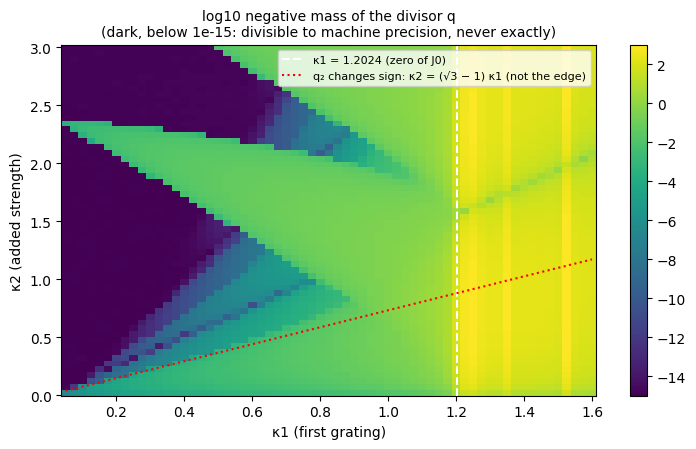

In [4]:
print(f"the wall: first zero of J0 is at 2κ = 2.4048, so κ = {KAPPA_WALL:.4f}")
print("\nnegative mass of the divisor q (0 = divisible to machine precision), κ2 = 0.1:")
print("  " + "   ".join(f"κ1={k1}: {negative_mass(k1, 0.1):.1e}" for k1 in [0.3, 0.6, 0.9, 1.1, 1.19, 1.21, 1.5]))

print("\npast the wall: |q̂| at the zero, for the special κ2 with κ1 + κ2 = κ1 j0k / j01 (must be ≤ 1 for a divisor):")
z = jn_zeros(0, 500)
print("  " + "   ".join(f"k={kk}: {abs(z[kk - 1] * jv(1, z[kk - 1])) / (z[0] * jv(1, z[0])):.3f}" for kk in [2, 3, 4, 10])
      + f"   min over k = 2..500: {min(abs(z[1:] * jv(1, z[1:]))) / (z[0] * jv(1, z[0])):.3f}")

print("\nsmall κ: the weight of q at a jump of ±2 changes sign near κ2 / κ1 = √3 − 1 = 0.732, but q_4 is still negative above it")
print("  " + "   ".join(f"κ2/κ1={r}: q_2 = {divisor_kernel(0.1, 0.1 * r)[2]:+.1e}" for r in [0.5, 0.7, 0.75, 0.8, 1.0]))
print("  " + "   ".join(f"κ1=0.5, κ2/κ1={r}: q_4 = {divisor_kernel(0.5, 0.5 * r)[4]:+.1e}" for r in [0.8, 1.0, 1.15]))

print("\nbelow the wall the far weights alternate in sign (read off the real axis); signs of q_4 ... q_23:")
for k1, k2 in [(0.1, 0.3), (0.3, 1.0), (0.5, 1.5)]:
    w = far_weights(k1, k2, range(4, 24))
    print(f"  κ1 = {k1}, κ2 = {k2}:  " + "".join('+' if v > 0 else '−' for v in w) + f"   (q_10 = {w[6]:+.1e})")

print("\ninfinite divisibility needs log J0(2κ sin(θ/2)) to have non-negative jump weights; the weight λ₂ at ±2:")
th = 2 * np.pi * np.arange(4096) / 4096
lam2 = lambda kap: np.real(np.fft.ifft(np.log(char_fn(kap, th))))[2]
print("  " + "   ".join(f"κ={kap}: λ₂ = {lam2(kap):+.2e} (−κ⁴/64 = {-kap ** 4 / 64:+.2e})" for kap in [0.01, 0.3, 0.9, 1.19]))

print("\ncross-check with the linear program over all stochastic Λ (M = 48; 0 = feasible to solver tolerance):")
for k1, k2 in [(0.1, 0.3), (0.3, 1.0), (0.5, 2.0), (1.0, 1.0), (1.5, 1.5)]:
    resid = _intermediate_lp(gamma(grating(k1 + k2, 48)), gamma(grating(k1, 48)), True)[1]
    print(f"  κ1 = {k1}, κ2 = {k2}:  LP residual {max(resid, 0) if resid > 1e-6 else 0:.1e}   negative mass {negative_mass(k1, k2):.1e}")

k1s = np.linspace(0.05, 1.6, 63)
k2s = np.linspace(0.02, 3.0, 60)
Z = np.array([[np.log10(max(negative_mass(a, b), 1e-15)) for a in k1s] for b in k2s])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.pcolormesh(k1s, k2s, Z, shading='auto', cmap='viridis', vmin=-15, vmax=3)
ax.axvline(KAPPA_WALL, color='w', ls='--', label='κ1 = 1.2024 (zero of J0)')
ax.plot(k1s, (np.sqrt(3) - 1) * k1s, 'r:', label='q₂ changes sign: κ2 = (√3 − 1) κ1 (not the edge)')
ax.set_xlabel('κ1 (first grating)'); ax.set_ylabel('κ2 (added strength)')
ax.set_title('log10 negative mass of the divisor q\n(dark, below 1e-15: divisible to machine precision, never exactly)', fontsize=10)
ax.legend(fontsize=8, loc='upper right')
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

### 📖 In depth: why the wall is at 1.2024

If $\Gamma(\kappa_1+\kappa_2) = q * \Gamma(\kappa_1)$, then in Fourier space $\hat\Gamma(\kappa_1+\kappa_2) = \hat q\,\hat\Gamma(\kappa_1)$. Where $\hat\Gamma(\kappa_1) = J_0(2\kappa_1 s)$ is zero, the left side must be zero too, and
generically it isn't. $J_0$ first vanishes at 2.4048, and $2\kappa_1 s$ reaches it for some $s = \sin(\theta/2) \le 1$ once $\kappa_1 \ge 1.2024$. Past that, a divisor needs the numerator to vanish
at the same θ, which happens only for special $\kappa_2$ ($\kappa_1 + \kappa_2 = \kappa_1 j_{0,k}/j_{0,1}$, $k \ge 2$). Even then, by l'Hôpital's rule $\hat q$ at that point equals
$j_{0,k}J_1(j_{0,k})/(j_{0,1}J_1(j_{0,1}))$, which has size at least 1.50 (the printout), while the transform of a probability distribution never exceeds 1 in size. So no divisor exists past
the wall. The ingredients are classical (the factor criterion for characteristic functions, and $|\hat q| \le 1$); their application to this kernel was not found in our searches. Just before the wall, $\hat q$ becomes huge and $q$ swings negative. On the finite ring the defect past the wall depends on how
close a sampled θ falls to the zero, hence the vertical stripes.

**Below the wall: divisible to machine precision, never exactly.** Continue $\hat q$ to complex θ. The numerator is entire; the denominator $J_0(2\kappa_1\sin(\theta/2))$ vanishes where
$\sin(\theta/2) = j_{0,m}/2\kappa_1 > 1$, i.e. on the line $\mathrm{Re}\,\theta = \pi$; the nearest is at $\theta = \pi \pm i y_1$ with $y_1 = 2\,\mathrm{arccosh}(j_{0,1}/2\kappa_1)$, unless the numerator
vanishes there too (when $(\kappa_1+\kappa_2)/\kappa_1 = j_{0,k}/j_{0,1}$), in which case the next pole takes over. A Fourier series is governed at large $n$ by its nearest singularities,
so $q_n \approx C(-1)^n e^{-n y}$ with $C$ real and $y$ the distance of the nearest surviving pole: the far weights alternate in sign and $q$ always has negative entries. They are tiny (at $\kappa_1 = 0.3$, $\kappa_2 = 1.0$, $q_{10} \approx -9\times10^{-20}$),
far below double precision on the real axis, which is why the map and the linear program show a dark "divisible" region. The bands inside it are where negative weights are large enough to see.

**Infinite divisibility.** A grating that came from a shift-invariant Markov process in κ would have a transform $e^{\kappa\,\hat L(\theta)}$, with $\hat L$ the transform of a rate kernel: non-negative
weights on every jump. So $\log J_0(2\kappa s)$ would need non-negative jump weights. It never has them for $\kappa > 0$. Expanding, $\log J_0(2\kappa s) \approx -\kappa^2 s^2 - \kappa^4 s^4/4$, and $s^4 = (1-\cos\theta)^2/4$
contains $\cos 2\theta/8$, so the weight on a jump of ±2 is $\lambda_2 \approx -\kappa^4/64$. The printout shows it stays negative up to the wall; past the wall $J_0$ has a zero and an exponential
never does. So no grating splits into arbitrarily many identical shift-invariant steps.

**Small κ.** Taking logs, $\log\hat q \approx -a s^2 - (b/4)s^4$ with $a = c^2 - \kappa_1^2$ and $b = c^4 - \kappa_1^4$, where $c = \kappa_1 + \kappa_2$. The $s^2$ term alone is a random walk, all jumps positive. In
$\hat q \approx 1 - a s^2 + (a^2/2 - b/4)s^4$ only the $s^4$ term reaches a jump of ±2, so $q_2 \propto a^2/2 - b/4 = (c^2 - \kappa_1^2)(c^2 - 3\kappa_1^2)/4$. It changes sign at $c = \sqrt3\,\kappa_1$, i.e.
$\kappa_2 = (\sqrt3 - 1)\kappa_1$. That is where $q_2$ turns positive, not the edge of the dark region: the same expansion carried further gives $q_4 < 0$ up to $\kappa_2 \approx 1.19\,\kappa_1$ and
$q_6$, $q_8$ negative up to about $1.30\,\kappa_1$ (the printout shows $q_4 \approx -2\times10^{-6}$ at $\kappa_1 = 0.5$, $\kappa_2 = 0.5$). The red dotted line on the map marks only the sign change of $q_2$.

<!-- expansion:16:recap-3 -->
### 📝 Recap: section 3

- Divisible from $\kappa_1$ to $\kappa_1 + \kappa_2$ iff $q$, with $\hat q = J_0(2(\kappa_1+\kappa_2)s)/J_0(2\kappa_1 s)$, has no negative entries.
- Past $\kappa_1 = 1.2024$: no divisor exists (a short argument: it would need $|\hat q| \ge 1.50$).
- Below it: a large region divisible to machine precision (negative weights below $10^{-15}$; the linear program agrees), but never exactly: the far weights of $q$ alternate in sign.
- $q_2 \propto (c^2 - \kappa_1^2)(c^2 - 3\kappa_1^2)$ changes sign at $\kappa_2 = (\sqrt3 - 1)\kappa_1$; this is not the edge of the dark region, since $q_4$, $q_6$, $q_8$ stay negative beyond it.
- No grating splits into arbitrarily many identical shift-invariant steps for any $\kappa > 0$: the jump weight $\lambda_2 \approx -\kappa^4/64$ is negative all the way to the wall.


## 4. The Talbot Effect: a Step That Does Nothing

Now separate the gratings by a free flight of time $t$. A free flight multiplies each momentum by a phase $e^{-ip^2t/2}$, so in the momentum basis its Γ is the identity: on its own it moves no
probability. Any Markov composite of grating, flight and grating therefore gives the same answer for every $t$. In these units ($\hbar = m = 1$, grating period $2\pi$) the Talbot time is
$T = 4\pi$, when every phase $e^{-ip^2t/2}$ returns to 1.

Start at rest and ask for the chance of being back at rest after the second grating.

flight Γ is the identity: True
Markov composite, any t:  P(back at rest) = Σ J_m(1.5)⁴ = 0.268
  t = 0.000 × Talbot time:  P(back at rest) = 0.068
  t = 0.125 × Talbot time:  P(back at rest) = 0.283
  t = 0.250 × Talbot time:  P(back at rest) = 0.534
  t = 0.375 × Talbot time:  P(back at rest) = 0.558
  t = 0.500 × Talbot time:  P(back at rest) = 1.000
  t = 0.750 × Talbot time:  P(back at rest) = 0.534
  t = 1.000 × Talbot time:  P(back at rest) = 0.068

half Talbot, κ1 = 1.5, κ2 = 0.5: matches one grating of κ1 − κ2 = 1.0: True
full Talbot, κ1 = 1.5, κ2 = 0.5: matches one grating of κ1 + κ2 = 2.0: True


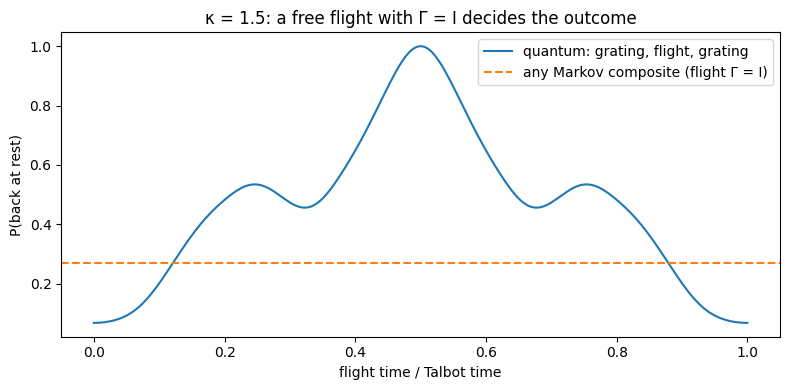

In [5]:
k = 1.5
print(f"flight Γ is the identity: {np.allclose(gamma(flight(1.234, M)), np.eye(M))}")
markov = (gamma(grating(k, M)) @ gamma(grating(k, M)))[0, 0]
print(f"Markov composite, any t:  P(back at rest) = Σ J_m(1.5)⁴ = {markov:.3f}")
for frac in [0, 1 / 8, 1 / 4, 3 / 8, 1 / 2, 3 / 4, 1]:
    print(f"  t = {frac:.3f} × Talbot time:  P(back at rest) = {two_gratings(k, k, frac * TALBOT)[0]:.3f}")

print(f"\nhalf Talbot, κ1 = 1.5, κ2 = 0.5: matches one grating of κ1 − κ2 = 1.0: "
      f"{np.allclose(two_gratings(1.5, 0.5, TALBOT / 2), jv(p, 1.0) ** 2)}")
print(f"full Talbot, κ1 = 1.5, κ2 = 0.5: matches one grating of κ1 + κ2 = 2.0: "
      f"{np.allclose(two_gratings(1.5, 0.5, TALBOT), jv(p, 2.0) ** 2)}")

ts = np.linspace(0, TALBOT, 241)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ts / TALBOT, [two_gratings(k, k, t)[0] for t in ts], label='quantum: grating, flight, grating')
ax.axhline(markov, color='C1', ls='--', label='any Markov composite (flight Γ = I)')
ax.set_xlabel('flight time / Talbot time'); ax.set_ylabel('P(back at rest)')
ax.set_title('κ = 1.5: a free flight with Γ = I decides the outcome'); ax.legend()
plt.tight_layout(); plt.show()

### 📖 In depth: why half the Talbot time undoes the grating

At $t = 2\pi$ the flight phase is $e^{-ip^2\pi} = (-1)^p$, because $p^2$ and $p$ have the same parity. Multiplying momentum $p$ by $(-1)^p$ is the same as shifting the atom by half a period, $x \to x + \pi$.
The second grating then sees $\cos(x+\pi) = -\cos x$: it acts with strength $-\kappa_2$. With equal strengths the two gratings cancel and the atom ends up at rest.

At the full Talbot time every flight phase is 1, and the two gratings add. In between, the flight phases are scrambled and the result is somewhere in between. None of this shows in the flight's
Γ, which is the identity at every $t$.

<!-- expansion:16:recap-4 -->
### 📝 Recap: section 4

- The flight's Γ is the identity at every $t$; any Markov composite predicts 0.268.
- The real chance of returning to rest runs from 0.068 (no flight, or a full Talbot time) to 1 (half the Talbot time).
- At half the Talbot time the gratings subtract; at the full Talbot time they add.


## 5. The Same Experiment in the Position Basis

Swap the roles: take position as the configuration. Now each grating is a phase on each position and has $\Gamma = I$, while the flight moves probability.

Multiplying the evolution matrix by diagonal phases on each side, $\Theta \to D_1\Theta D_0^\dagger$, leaves Γ unchanged. This is a special case of two gauge transformations in Barandes's
Paper 3: a Schur–Hadamard gauge transformation (§3.2, eqs. 29–30, with $\theta_{ij} = g_i - h_j$; see notebook 15) and a Foldy–Wouthuysen gauge transformation (§3.6, eq. 74, with diagonal
$V$). Calling the end-gratings a special case of these is the lab's reading, not Barandes's example. Check that, and contrast it
with inserting the same phases between two flights. That second case changes the dynamics; it is not a re-description of one evolution matrix.

In [6]:
D = F.conj().T @ flight(np.pi, M) @ F                     # a flight of π, in the position basis
g = np.diag(np.exp(-1j * 1.5 * np.cos(x)))                # a grating, in the position basis
print(f"grating on both ends,  g D g  vs  D:     max change in Γ = {np.abs(gamma(g @ D @ g) - gamma(D)).max():.1e}")
print(f"grating in the middle, D g D  vs  D D:   max change in Γ = {np.abs(gamma(D @ g @ D) - gamma(D @ D)).max():.3f}")

grating on both ends,  g D g  vs  D:     max change in Γ = 3.3e-16
grating in the middle, D g D  vs  D D:   max change in Γ = 0.995


### 📖 In depth: gauge at the ends only

Phases on positions before the first step, or after the last, multiply the evolution matrix row by row or column by column; the moduli of its entries don't change, so Γ doesn't. That is a
special case of both of Barandes's gauge freedoms: Schur–Hadamard (Paper 3 eq. 30 with $\theta_{ij} = g_i - h_j$) and Foldy–Wouthuysen (eq. 74 with a diagonal $V$). Between two
flights the same phases get mixed by the second flight and do change Γ. This is what Barandes says: his phases $\theta_{ij}(t)$ apply to each $\Theta(t \leftarrow 0)$ separately and touch only
Hilbert-space ingredients (Paper 3 eqs. 29–30). A grating inserted mid-flight is a change of the dynamics, not a re-description of one evolution matrix, so the 0.995 is a clarification
of where his gauge freedom applies, not a counterexample to it. Notebook 15 found the same thing with the flux: phases that cancel at the ends survive round a loop.

<!-- expansion:16:recap-5 -->
### 📝 Recap: section 5

- In the position basis, gratings at the ends drop out of Γ: a special case of Barandes's Schur–Hadamard (Paper 3 §3.2) and Foldy–Wouthuysen (§3.6) gauge transformations.
- A grating between two flights changes Γ by up to 0.995. That is a change of the dynamics, not a Schur–Hadamard transformation (those act on each $\Theta(t \leftarrow 0)$ separately,
  Paper 3 eqs. 29–30), so it is consistent with Barandes.


## 6. Records

Record something during the flight, halfway, with strength $\varepsilon$ (0 = no record, 1 = a full record), at half the Talbot time with $\kappa_1 = \kappa_2 = 1.5$.
- **A momentum record** multiplies every coherence between momenta by $1 - \varepsilon$: at $\varepsilon = 1$ a division event in the configuration basis; for $\varepsilon < 1$ a mixture of that
  and no record.
- **A position record** of resolution $\ell$ multiplies the coherence between positions $x$ and $y$ by $1 - \varepsilon\,(1 - w(x-y))$, with $w$ a Gaussian of width $\ell$ (wrapped round the
  ring). It models an atom scattering a gas molecule or a photon whose wavelength sets $\ell$. The grating period is $2\pi \approx 6.3$.

momentum record:  ε=0: 1.000   ε=0.25: 0.817   ε=0.5: 0.634   ε=1.0: 0.268    (Markov composite 0.268)
position record, ℓ =  0.3:  ε=0.25: 0.790   ε=0.5: 0.581   ε=1.0: 0.161
position record, ℓ =  1.0:  ε=0.25: 0.864   ε=0.5: 0.728   ε=1.0: 0.455
position record, ℓ =  2.0:  ε=0.25: 0.953   ε=0.5: 0.906   ε=1.0: 0.811
position record, ℓ =  3.0:  ε=0.25: 0.995   ε=0.5: 0.990   ε=1.0: 0.981


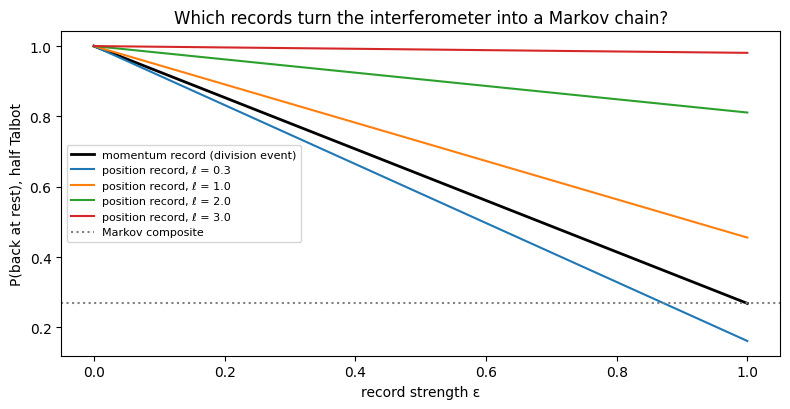

In [7]:
k, t = 1.5, TALBOT / 2
print("momentum record:  " + "   ".join(f"ε={e}: {two_gratings(k, k, t, eps=e)[0]:.3f}" for e in [0, 0.25, 0.5, 1.0])
      + f"    (Markov composite {markov:.3f})")
for ell in [0.3, 1.0, 2.0, 3.0]:
    print(f"position record, ℓ = {ell:4}:  " + "   ".join(
        f"ε={e}: {two_gratings(k, k, t, eps=e, basis='position', ell=ell)[0]:.3f}" for e in [0.25, 0.5, 1.0]))

eps = np.linspace(0, 1, 21)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(eps, [two_gratings(k, k, t, eps=e)[0] for e in eps], 'k-', lw=2, label='momentum record (division event)')
for ell in [0.3, 1.0, 2.0, 3.0]:
    ax.plot(eps, [two_gratings(k, k, t, eps=e, basis='position', ell=ell)[0] for e in eps], label=f'position record, ℓ = {ell}')
ax.axhline(markov, color='grey', ls=':', label='Markov composite')
ax.set_xlabel('record strength ε'); ax.set_ylabel('P(back at rest), half Talbot')
ax.set_title('Which records turn the interferometer into a Markov chain?'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 📖 In depth: reading the records

- **Momentum records** are, at full strength ($\varepsilon = 1$), division events in the configuration basis: they keep the momentum distribution and remove the coherences between momenta. Halfway through, the
  result moves linearly from 1 (no record) to 0.268 (the Markov composite).
- **Position records** keep the momentum coherences in a different way. Seen from momentum, learning the position roughly means a random kick of size about $1/\ell$. A record of width $\ell$
  and strength ε, with probability ε, kicks by $n$ units ($n = 0$ included) with weights proportional to $e^{-n^2\ell^2/2}$; the kicks are whole units of momentum ($2\hbar k_L$). A coarse record ($\ell = 3$, about half the period 6.3) almost never kicks and
  leaves the refocusing almost intact. A fine record gives large kicks: the interference goes, and the kicks also spread the atom, so
  the return probability falls below the Markov value.
- This is the logic of decoherence experiments with large molecules, where the wavelength of the scattered gas molecules or emitted photons decides whether the fringes survive. The model is
  the standard one for Talbot–Lau decoherence (Hornberger, Sipe and Arndt (2004)).

<!-- expansion:16:derive-records -->
### 🧮 Worked derivation: why the momentum record is linear

Write the state halfway through as $\rho$. A momentum record of strength ε gives

$$\rho \to (1-\varepsilon)\,\rho + \varepsilon\,\mathrm{diag}(\rho).$$

Everything after the record is linear in ρ, so the final probability is $(1-\varepsilon)P_{\text{no record}} + \varepsilon\,P_{\text{full record}}$. With a full record, the atom's momentum is known halfway, the
two halves of the flight do nothing to it, and the result is the Markov composite $\sum_m J_m(1.5)^4 = 0.268$. So the line runs from 1 to 0.268.

A position record is also linear in ε, but its end point is not the Markov composite. It multiplies the position-basis coherences by a function of $x - y$, which in the momentum basis is
a random shift of momentum applied to the whole state: a kick, not a division event.


<!-- expansion:16:recap-6 -->
### 📝 Recap: section 6

- Momentum records (division events in the configuration basis at full strength) move the result linearly from the quantum value to the Markov composite, reached at ε = 1.
- Position records are random kicks in momentum: coarse ones do little, fine ones do more than a division event.


### 🔭 Looking ahead

**Connections.**
- Notebook 05: interference in Γ; this notebook is the momentum-space version, with an exact divisibility test.
- Notebooks 03 and 08: the linear program used in section 3 to check the Fourier test.
- Notebook 11: the dense-record limit; a grating chopped into many thin slices with records in between gives a momentum random walk.
- Notebook 15: Schur–Hadamard gauge, and phases that survive only round loops or between stages.

**Possible extensions.** Thick gratings (the Bragg regime); a real Talbot–Lau setup with three gratings and an incoherent source; a time-resolved collisional decoherence model.

**Prior work (checked 2026-10-29).**
- Kapitza & Dirac, Proc. Camb. Phil. Soc. 29, 297 (1933) (cited by Schleich, p. 576); Gould, Ruff & Pritchard, Phys. Rev. Lett. 56, 827 (1986).
- The $J^2_n$ kernel: known as the continuous-time quantum walk on the integers, $\rho(t, x) = J_x(t)^2$ (de Falco and Tamascelli, arXiv:0801.4515, eqs. 1–3; they also build a Markov
  birth–death process with these marginals from rest, eqs. 12–18). Graf's theorem as its transform: DLMF §10.23, which has both addition theorems.
- The divisibility test itself: the classical factor criterion (a distribution is a convolution factor of another iff the ratio of their characteristic functions is a characteristic
  function), and the classical fact that an infinitely divisible characteristic function never vanishes; Lukacs, *Characteristic Functions*.
- Half- and full-Talbot behaviour: the antiresonance and resonance of the quantum kicked rotor (arXiv:1202.3166; arXiv:0806.3107).
- Talbot, Phil. Mag. 9, 401 (1836) and Clauser & Li, Phys. Rev. A 49, R2213 (1994) (both cited by Schleich, p. 253); Brezger et al., Phys. Rev. Lett. 88, 100404 (2002);
  Gerlich et al., Nature Physics 3, 711 (2007).
- Position records as Talbot–Lau decoherence: Hornberger, Sipe and Arndt (2004); the review by Hornberger and co-authors, arXiv:1109.5937; experiments in Hornberger et al.,
  Phys. Rev. Lett. 90, 160401 (2003) and Hackermüller et al., Nature 427, 711 (2004).
- The application of these to the Kapitza–Dirac momentum Γ (section 3: the bound $|\hat q| \ge 1.50$ past κ = 1.2024, the alternating far weights below it, $\lambda_2 < 0$):
  not found in our searches (2026-10-29; 2026-11-05: "quantum walk Bessel divisible", "squared Bessel infinitely divisible", "Kapitza–Dirac Markov random walk"). Still to check: the
  kicked-rotor random-phase literature (Cohen, Phys. Rev. A 44, 2292).

## Summary

- **One grating is a Bessel kernel.** In the momentum basis $\Gamma_{pq} = J^2_{p-q}(\kappa)$, the same from every starting momentum; in the position basis the grating has $\Gamma = I$.
- **Amplitudes compose, probabilities don't.** Gratings add their strengths exactly (Neumann's addition theorem); the Markov composite of their Γ's is wrong, by a total variation
  distance of 0.08 at $\kappa = 0.3 + 0.3$ and 0.36 at $1.5 + 1.5$. The probabilities obey Graf's theorem instead: their Fourier transform is $J_0(2\kappa\sin(\theta/2))$.
- **An exact divisibility test, and a wall.** Because Γ is translation invariant, the family is divisible from $\kappa_1$ to $\kappa_1 + \kappa_2$ exactly when one ratio of Bessel functions is the
  Fourier transform of a probability distribution (the classical factor criterion for characteristic functions). Past $\kappa_1 = 1.2024$, where $J_0$ first vanishes, no divisor exists for any $\kappa_2$: a short argument (not found in our searches)
  shows it would need $|\hat q| \ge 1.50$. Below the wall the family is never exactly divisible either: $\hat q$ has complex poles on $\mathrm{Re}\,\theta = \pi$ (the nearest at
  $\pi \pm 2i\,\mathrm{arccosh}(j_{0,1}/2\kappa_1)$ unless the numerator cancels it), so its far weights alternate in sign. In a large region those negative weights are below $10^{-15}$, so the family is divisible to machine precision (and the linear program over all stochastic Λ
  reports "divisible"), never exactly. The weight at a jump of ±2, $q_2 \propto (c^2 - \kappa_1^2)(c^2 - 3\kappa_1^2)$ with $c = \kappa_1 + \kappa_2$, changes sign at $\kappa_2 = (\sqrt3 - 1)\kappa_1$, but this is
  not the edge of that region: $q_4$ stays negative up to $\kappa_2 \approx 1.19\,\kappa_1$ and $q_6$, $q_8$ up to about $1.30\,\kappa_1$ (leading order at small κ).
- **Never a Markov process in κ.** Since no pair of strengths is exactly divisible, no Markov process reproduces the full Γ(κ) from every starting momentum. (One that reproduces only the
  distribution from rest does exist: de Falco and Tamascelli's birth–death process, arXiv:0801.4515.) Separately, no single grating splits into arbitrarily many identical shift-invariant
  steps: the jump weight $\lambda_2$ of $\log J_0$ is negative for every κ up to the wall ($\approx -\kappa^4/64$ at small κ), and past the wall the transform vanishes, which no infinitely
  divisible law allows.
- **A step that does nothing decides everything.** The free flight has $\Gamma = I$ in the momentum basis, so every Markov composite predicts a return probability of 0.268 for every flight time. The
  real value runs from 0.068 to 1: at half the Talbot time the second grating exactly undoes the first. This is the same mechanism as $HZH = X$ versus $HH = I$ for a qubit, where $Z$ has $\Gamma = I$ yet flips the outcome.
- **Phases at the ends, and between flights.** In the position basis the gratings are phases on positions. At the ends of the experiment they are a special case of Barandes's Schur–Hadamard
  (Paper 3 §3.2) and Foldy–Wouthuysen (§3.6) gauge transformations, and drop out of Γ.
  Inserted between two flights they change Γ by up to 0.995. That does not contradict Barandes: his phases $\theta_{ij}(t)$ act on each $\Theta(t \leftarrow 0)$ separately and touch only
  Hilbert-space ingredients (Paper 3 eqs. 29–30). A grating inserted mid-flight changes the dynamics, so it is not such a transformation.
- **Records.** A momentum record moves the result linearly from the quantum value to the Markov composite (reached with a full record, $\varepsilon = 1$). A position record is not a division event for
  momentum: with probability $\varepsilon$ it kicks the momentum by $n$ units ($n = 0$ included), with weights $\propto e^{-n^2\ell^2/2}$. A coarse one ($\ell = 3$, half a period) barely matters (0.98), while a fine one ($\ell = 0.3$) destroys the interference and also spreads the atom,
  pushing the return probability below the Markov value (0.16).

Caveats: thin gratings only (no motion during the pulse), one period with periodic boundaries, a plane-wave atom.

Prior work: the $J^2_n$ kernel is the continuous-time quantum walk on the integers, $\rho = J_x(t)^2$ (de Falco and Tamascelli, arXiv:0801.4515, who also build a Markov process with those
marginals from rest); its transform $J_0(2\kappa\sin(\theta/2))$ is Graf's addition theorem (DLMF §10.23). The half- and full-Talbot behaviour is the antiresonance and resonance of the quantum
kicked rotor (arXiv:1202.3166; arXiv:0806.3107). The position-record model is Talbot–Lau decoherence (Hornberger, Sipe and Arndt (2004); the review by Hornberger and co-authors,
arXiv:1109.5937). The divisibility test of section 3 is the classical factor criterion: a divisor exists iff the ratio of characteristic functions is itself a characteristic function; and
an infinitely divisible law's characteristic function never vanishes (both in Lukacs, *Characteristic Functions*). Not found in our searches (2026-10-29 and 2026-11-05): the application of
these to the Kapitza–Dirac kernel (the bound $|\hat q| \ge 1.50$ past the wall, the alternating far weights below it, $\lambda_2 < 0$).

### 📖 In depth: the one-paragraph version

A thin light grating spreads an atom's momentum by a Bessel kernel, $\Gamma_{pq} = J^2_{p-q}(\kappa)$. Gratings add exactly for amplitudes but not for probabilities, and because Γ is the same from
every starting momentum, whether the family is divisible reduces to one Fourier test (the classical factor criterion): past $\kappa = 1.2024$, where $J_0$ vanishes, no divisor exists; below it a large region passes to machine
precision, but the divisor's far weights alternate in sign, so the family is never exactly divisible, and no grating is infinitely divisible. Put a free flight between two gratings: its Γ is
the identity, so a Markov model says it can't matter, yet at half the Talbot time it makes the second grating exactly undo the first. Full records of momentum turn the interferometer into a Markov
chain; records of position act as random kicks instead.

<!-- expansion:16:check -->
### 📝 Check your understanding

1. *Why is one grating's Γ the same from every starting momentum?*
   The grating multiplies the wavefunction by a function of position; in momentum that is a set of kicks $n$ with amplitudes that don't depend on the starting momentum.
2. *Why can't you compose gratings by multiplying their Γ's?*
   Strengths add for amplitudes; squaring each term of Neumann's sum loses the cross terms.
3. *Why is the divisibility test a single Fourier transform here?*
   Averaging any divisor over shifts gives a convolution divisor, and a convolution is a product in Fourier space, so the divisor is fixed.
4. *What happens at κ = 1.2024?*
   The Fourier transform of $\Gamma(\kappa_1)$ first reaches zero, and a product can't turn zero into the transform of $\Gamma(\kappa_1+\kappa_2)$ wherever that is nonzero. Only special
   $\kappa_2$ escape this argument, and for them $\hat q$ at that point has size at least 1.50, more than any probability distribution's transform allows. So no divisor exists past the wall.
   (Below the wall the family is not exactly divisible either: the divisor's far weights alternate in sign.)
5. *The flight's Γ is the identity. How can it matter?*
   It changes the phases between momenta, and the second grating turns phases into probabilities. Γ discards exactly the information the flight carries.
6. *Why doesn't a fine position record give the Markov composite?*
   It isn't a record of the configuration (momentum). Seen from momentum it is a random kick, which spreads the atom on top of destroying the interference.
